# Measurement recovery and recall alignment

Notebook 19 · Development only · Path A.

We execute the diagnostics supported by existing data. Missing prompt, acquisition and answer-version clocks keep prospective models blocked. Synthetic examples test behavior, not physiological validity. No final-test data or participant rows are displayed.

In [1]:
from pathlib import Path
import sys, json
root = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
sys.path.insert(0, str(root / 'src'))
from garmin_measurement_alignment.run import run
from IPython.display import display, Image, Markdown
import pandas as pd
pointer = run(root)
public = root / pointer['public']
display(Markdown('Aggregate sources: `' + pointer['public'] + '`; private provenance: `' + pointer['run'] + '`'))
def table(name):
    return pd.read_csv(public / (name + '.csv')) if (public / (name + '.csv')).exists() else pd.read_json(public / (name + '.json'))
def figure(name):
    display(Image(filename=str(public / 'figures' / (name + '.png'))))

Aggregate sources: `reports/measurement_alignment/e5359ea4cc4b4efa`; private provenance: `private/measurement_alignment/runs/e5359ea4cc4b4efa`

## Actual starts are not prompt delivery
All exported starts are available; this does not count unanswered prompts. Offset is local minus UTC, in minutes.

,delay_available,delay_gt_0_minutes,delay_gt_15_minutes,delay_gt_5_minutes,delay_gt_60_minutes,delay_median_minutes,delay_p25_minutes,delay_p75_minutes,delay_p95_minutes,minute_resolution,missing_schedule,missing_start,negative_delay,responses,second_resolution,survey
0,934,659,311,456,127,5.000000,0.000000,28.000000,118.000000,934,0,0,0,934,0,Endday
1,1838,1838,638,1087,209,6.391667,0.783333,28.479167,87.171667,0,0,0,0,1838,1838,Midday
2,934,734,386,548,140,10.000000,1.000000,39.000000,93.000000,934,0,0,0,934,0,Morning


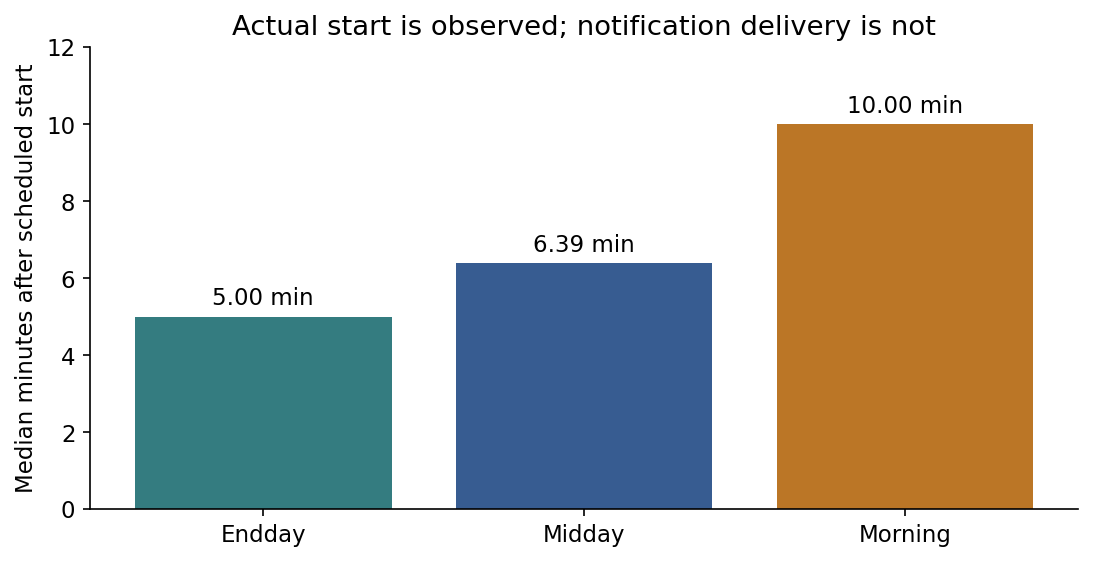

In [2]:
display(table('timing'))
figure('start_delays')

## Recall boundaries and the precision buffer
Minute start 09:22 → cutoff 09:21 → [09:16,09:21). Second start 09:22:35 → [09:17:35,09:22:35). These are synthetic examples. Morning asks since waking; Midday/Endday since last prompt. Never substitute a completed response or arbitrary 24-hour interval.

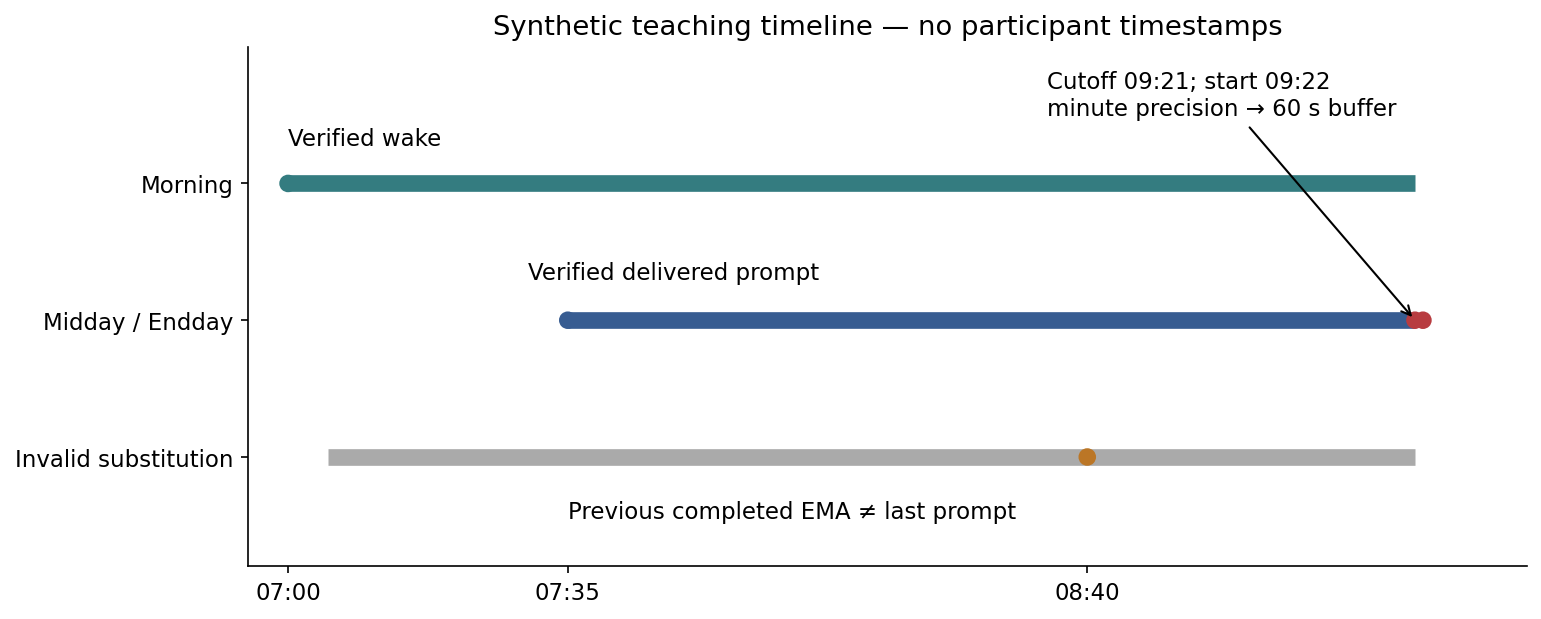

,denominator,development_missing,field,meaning,precision,source,status,synthetic_example
0,3706,0,actual_start_local,"actual survey start, not delivery/submission",minute/second,private/preprocessing/normalized/31e51c934bcde...,verified,2030-01-01 09:22
1,3706,0,scheduled_start_local,"exported schedule, not verified notification",minute/second,private/preprocessing/normalized/31e51c934bcde...,verified,2030-01-01 09:20
2,3706,0,timezone_offset,local minus UTC in minutes,numeric minutes,private/preprocessing/normalized/31e51c934bcde...,verified,-240
3,3706,0,instance_id,export instance key; not a delivered-prompt ev...,identifier,private/preprocessing/normalized/31e51c934bcde...,provisional,SYNTHETIC_INSTANCE
4,3706,0,rsp_id,response identifier; mapping preserved,identifier,private/preprocessing/normalized/31e51c934bcde...,provisional,SYNTHETIC_RESPONSE
5,3706,0,mbl_cod,participant identity via frozen verified cross...,identifier,private/preprocessing/normalized/31e51c934bcde...,verified,SYNTHETIC_PERSON
6,3706,2779,MORNING_SURVEY_COMPLETED,"status field, not completion timestamp",categorical,private/preprocessing/normalized/31e51c934bcde...,provisional,synthetic status
7,3706,2775,SLEEP_WAKETIME,"current-response waking answer, retrospective ...",clock text,private/preprocessing/normalized/31e51c934bcde...,provisional,07:30
8,3706,1526,Location Timestamp,"location clock, not survey delivery/completion",unverified,private/preprocessing/normalized/31e51c934bcde...,unsupported,synthetic location time
9,3706,0,n_actual_utc,actual_start_local minus row offset,derived,private/preprocessing/normalized/31e51c934bcde...,verified,2030-01-01T13:22Z


,sensor,field,records,missing
0,hr,data_type,15618530,0
1,hr,dte_tme,15618530,0
2,hr,mbl_cod,15618530,1738873
3,hr,rsp_id,15618530,92464
4,hr,ts,15618530,0
5,hr,val,15618530,0
6,steps,data_type,1063305,0
7,steps,dte_tme,1063305,0
8,steps,mbl_cod,1063305,104441
9,steps,rsp_id,1063305,6156


In [3]:
figure('synthetic_timeline')
display(table('field_audit').fillna(''))
display(table('sensor_field_availability'))

## Recording evidence
Cadence, repeats and gaps are observations. Periodic reporting, change-triggered output and delayed uploads remain competing interpretations. Step reset/rejection breaks remain intact; no missing period becomes zero activity.

,adjacent_pairs,finite_clocks,fractional_timestamps,gap_gt_2_seconds,gap_gt_300_seconds,gap_gt_3600_seconds,gap_gt_60_seconds,median_of_participant_median_gap_seconds,participants,records,repeated_value_adjacent,sensor,source_order_reversals,timestamp_repeat_pairs
0,15618159,15618282,15617032,3006889,4723,2675,7130,1.050389,123,15618282,1498279,hr,0,22
1,1063170,1063293,1063188,123849,19229,3283,48834,1.049694,123,1063293,9473,steps,0,2


,accepted_pairs,negative_reset_pairs,positive_accepted_pairs,records,zero_change_accepted_pairs
0,1043879,884,1037915,1063291,5964


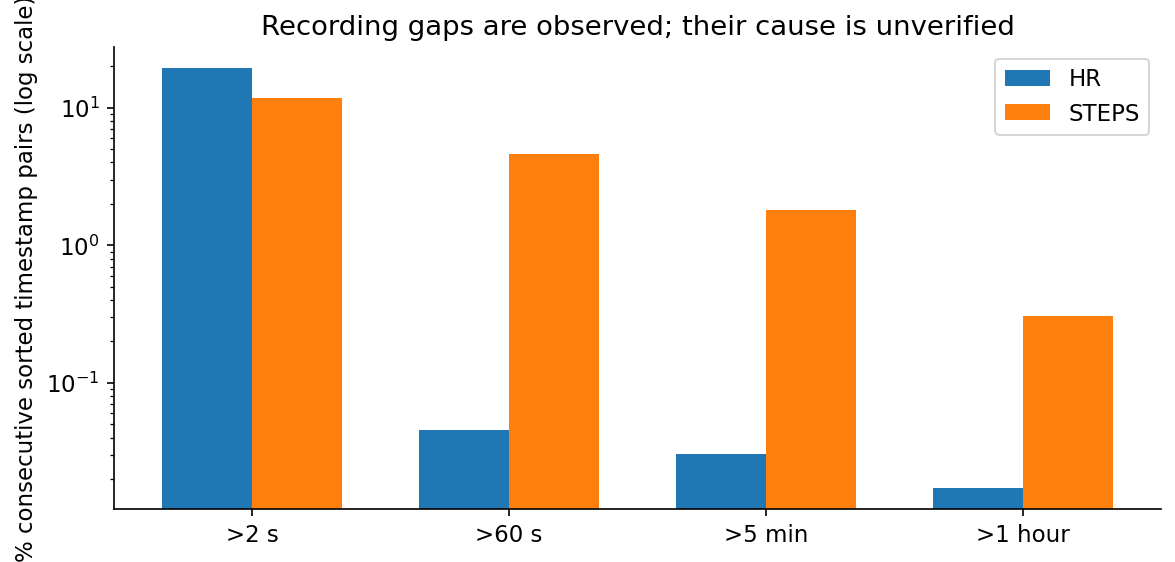

In [4]:
display(table('cadence'))
display(pd.DataFrame([json.loads((public / 'counters.json').read_text())]))
figure('cadence')

## Coverage and selection
All 3,706 responses remain counted. Accepted HR readings and supported counter pairs are distinct availability definitions. Sparse survey/time strata limit adjusted bootstrap inference.

,grouping,sensor,lookback_minutes,responses,participants,availability_definition,any_recorded,any_accepted,occupied_fraction_median,accepted_readings_median,gap_median_seconds,freshness_median_seconds,supported_seconds_median
0,sensor/lookback_minutes,floors,5,3706,125,supported_counter_pair,234,54,NaN,NaN,NaN,NaN,0.000000
1,sensor/lookback_minutes,floors,15,3706,125,supported_counter_pair,443,109,NaN,NaN,NaN,NaN,0.000000
2,sensor/lookback_minutes,floors,30,3706,125,supported_counter_pair,654,185,NaN,NaN,NaN,NaN,0.000000
3,sensor/lookback_minutes,floors,60,3706,125,supported_counter_pair,953,352,NaN,NaN,NaN,NaN,0.000000
4,sensor/lookback_minutes,floors,120,3706,125,supported_counter_pair,1357,607,NaN,NaN,NaN,NaN,0.000000
5,sensor/lookback_minutes,floors,360,3706,125,supported_counter_pair,2383,1236,NaN,NaN,NaN,NaN,0.000000
6,sensor/lookback_minutes,floors,720,3706,125,supported_counter_pair,2856,1634,NaN,NaN,NaN,NaN,0.000000
7,sensor/lookback_minutes,floors,1440,3706,125,supported_counter_pair,3317,2419,NaN,NaN,NaN,NaN,170.418604
8,sensor/lookback_minutes,hr,5,3706,125,accepted_reading,1520,1498,0.000000,0.0,300.000000,0.778401,NaN
9,sensor/lookback_minutes,hr,15,3706,125,accepted_reading,1598,1554,0.000000,0.0,900.000000,0.807856,NaN


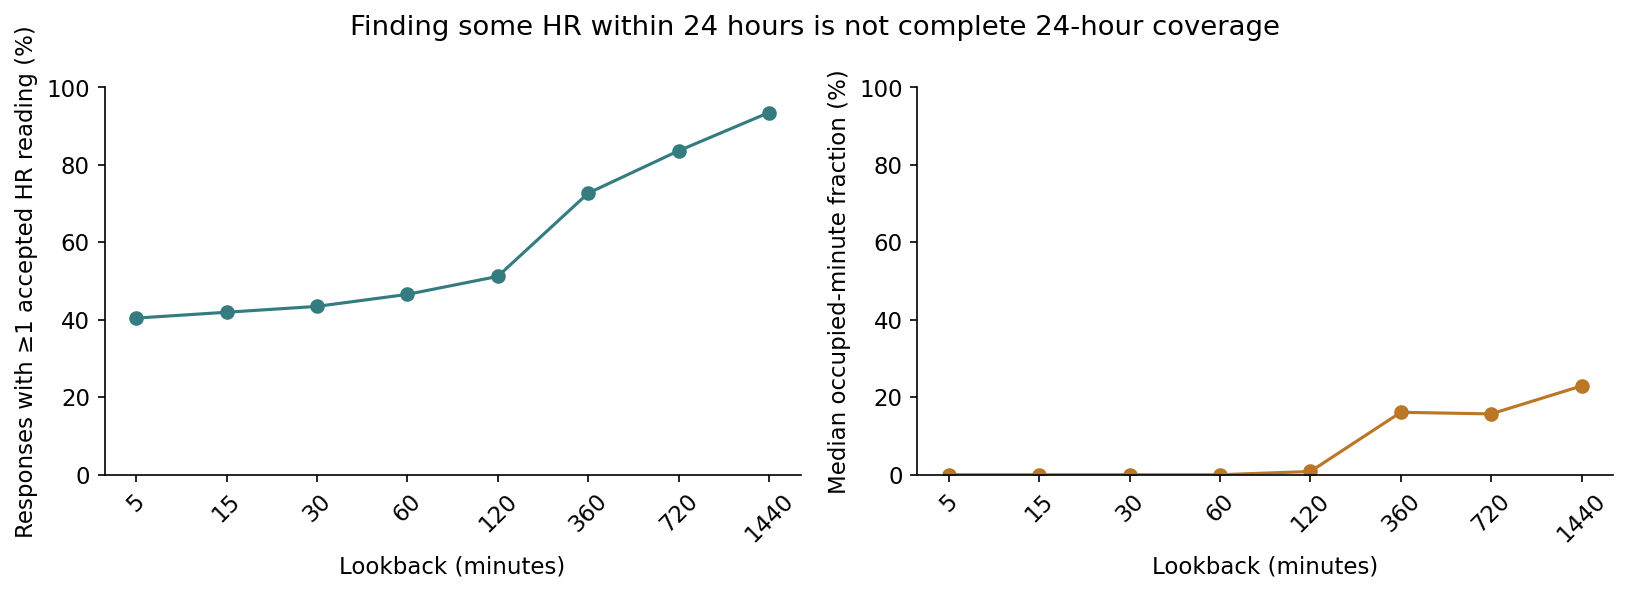

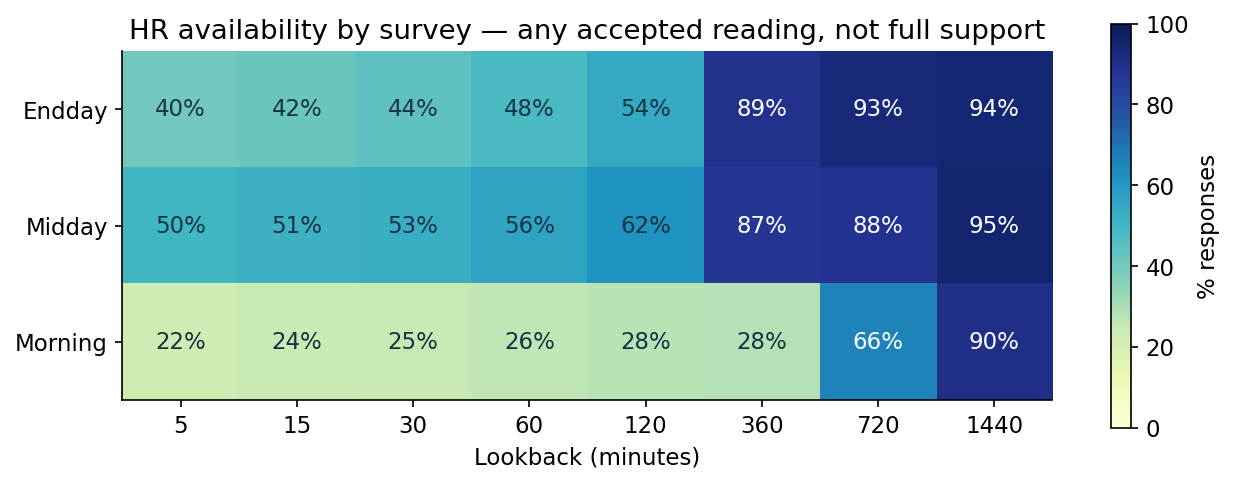

,crude_difference,crude_difference_draws,crude_difference_high,crude_difference_low,overlap_strata,participants,responses,sensor,standardized_responses,survey_time_standardized_difference,survey_time_standardized_difference_draws,survey_time_standardized_difference_high,survey_time_standardized_difference_low,threshold
0,-0.001334,2000,0.031629,-0.039013,11,125,3689,floors,3685,0.001843,672,0.034714,-0.032248,5
1,-0.013228,2000,0.018742,-0.045878,9,125,3689,floors,3681,-0.009871,1067,0.024140,-0.040433,10
2,0.016830,2000,0.090710,-0.063896,11,125,3689,hr,3685,0.029444,672,0.102213,-0.043442,5
3,-0.057686,2000,0.000895,-0.121692,9,125,3689,hr,3681,-0.045977,1067,0.011968,-0.107457,10
4,0.027522,2000,0.094185,-0.048029,11,125,3689,pulseox,3685,0.039582,672,0.102827,-0.028970,5
5,-0.027503,2000,0.028686,-0.088331,9,125,3689,pulseox,3681,-0.016966,1067,0.038476,-0.075994,10
6,-0.011307,2000,0.063810,-0.094129,11,125,3689,steps,3685,-0.001611,672,0.072092,-0.075727,5
7,-0.058057,2000,0.002507,-0.119669,9,125,3689,steps,3681,-0.048753,1067,0.015207,-0.107002,10


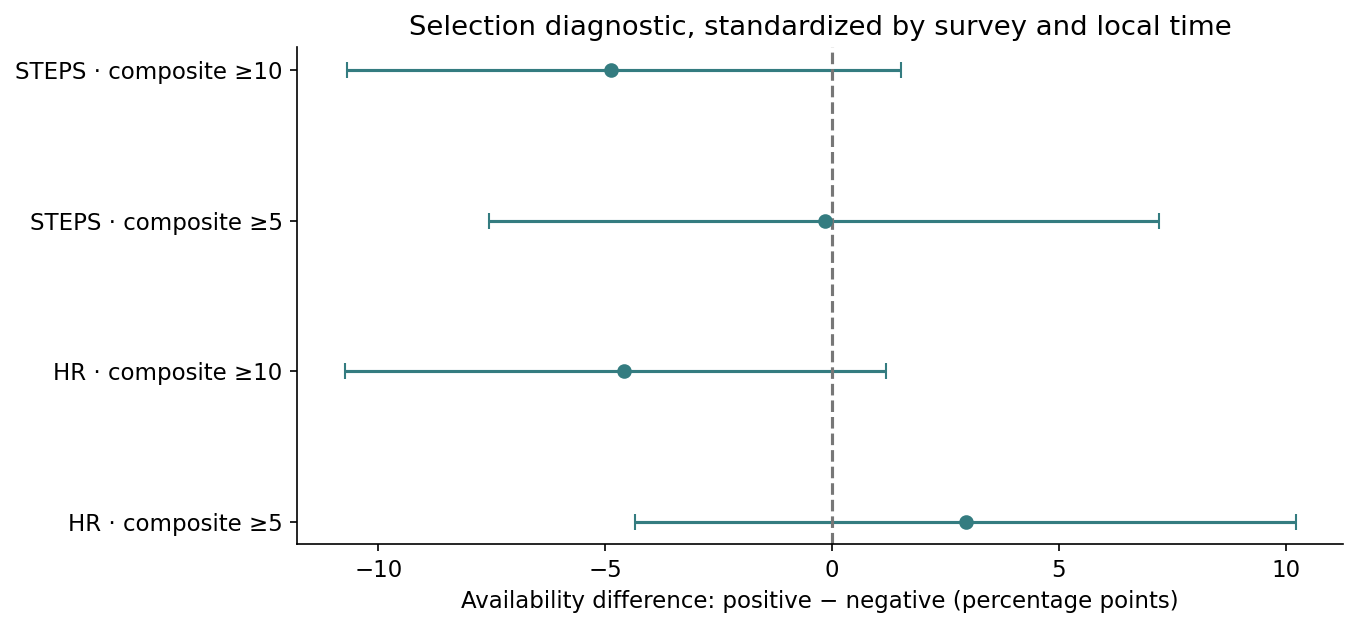

In [5]:
coverage = table('coverage')
display(coverage[coverage.grouping.eq('sensor/lookback_minutes')].dropna(axis=1, how='all'))
figure('coverage')
figure('survey_coverage')
display(table('availability_associations'))
figure('availability')

## Prespecified clock sensitivity
−60/0/+60 seconds changes support only. Original DURING/POST records cannot be pulled backwards into any scenario. No offset is selected and no AUROC is computed.

,lookback_minutes,shift_seconds,responses,responses_any_accepted,median_readings,mean_occupied_fraction,median_occupied_fraction
0,5,-60,3706,1495,0.0,0.302051,0.000000
1,5,0,3706,1498,0.0,0.374690,0.000000
2,5,60,3706,1417,0.0,0.367026,0.000000
3,15,-60,3706,1545,0.0,0.338946,0.000000
4,15,0,3706,1554,0.0,0.362493,0.000000
5,15,60,3706,1476,0.0,0.359273,0.000000
6,30,-60,3706,1606,0.0,0.340844,0.000000
7,30,0,3706,1610,0.0,0.352132,0.000000
8,30,60,3706,1536,0.0,0.350117,0.000000
9,60,-60,3706,1723,0.0,0.342840,0.000000


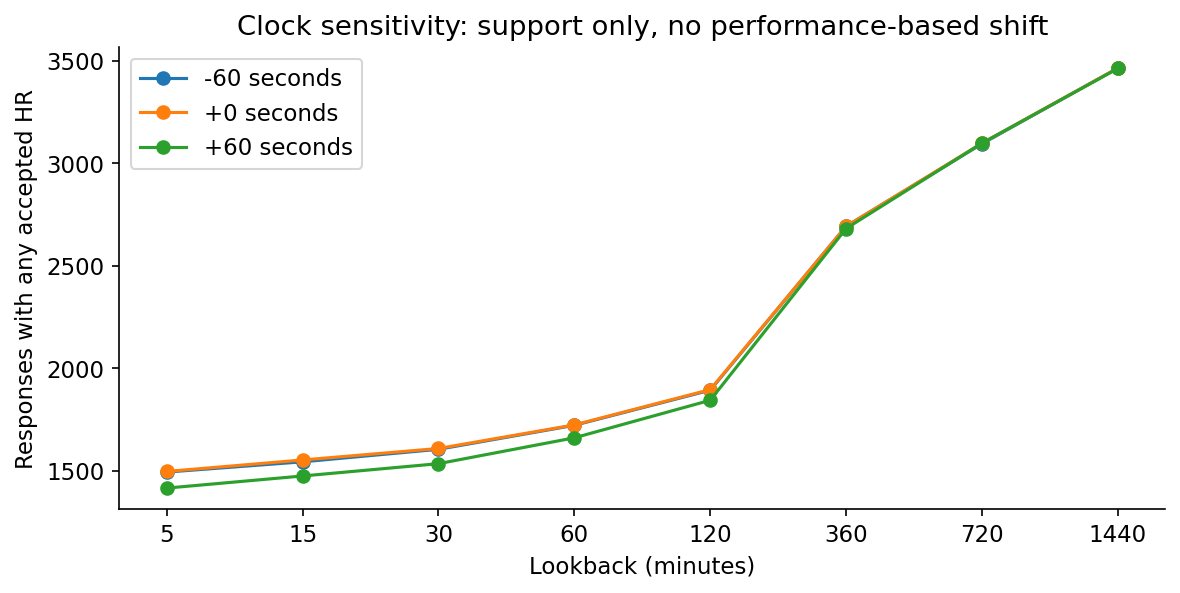

In [6]:
display(table('timing_sensitivity'))
figure('sensitivity')

## Verified behavior versus missing evidence
The typed importer requires separately approved hashes. Synthetic tests reject wrong identities, uncertain order, conflicting versions and future receipt; retain breaks; recover an injected signal across held-out synthetic participants. This does not validate real acquisition timestamps.

In [7]:
status = json.loads((public / 'status.json').read_text())
assert status['new_real_predictive_fits'] == 0
assert status['blocked_aligned'] == status['blocked_history'] == 3706
display(pd.DataFrame([status]))

,blocked_aligned,blocked_history,development_participants,development_responses,metadata_supplied,new_real_predictive_fits
0,3706,3706,125,3706,False,0


## Briefing and next step
The 53.5% within-person variation does not imply a wearable signal. Previous results are compared only on matching cohorts. Request the actual collector contract and complete prompt/version logs before the frozen conditional comparison. No provider messages were sent.

In [8]:
display(Markdown((root / 'reports/measurement_alignment/summary_for_will.md').read_text()))

# Notebook 19 — briefing for Will

**We have precise exported start clocks, but not verified sensor acquisition or delivered-prompt clocks.**
All available Path A diagnostics were executed; no new real predictive models were fit.

- All 3,706 development responses have actual/scheduled starts: 1,868 minute-resolution Morning/Endday and 1,838 second-resolution Midday.
- Median actual−scheduled delay: Morning 10.00 min; Midday 6.39 min; Endday 5.00 min. Starts >60 min after schedule: 140, 209 and 127 respectively. No missing starts among these exported responses; unanswered prompts are not observable from this denominator.
- At 60 min, 1,725 responses have any accepted HR; at 24 h, 3,464. Median 24-h occupied-minute fraction is 22.9%. Longer availability is not a verified recall interval or continuous coverage.
- HR and steps show roughly 1.05-second median participant cadence. Step pairs are overwhelmingly increasing; gaps, repeated values and fractional clocks cannot identify callback/batch/acquisition semantics. 884 negative counter pairs remain breaks, not negative activity.
- Availability/label differences are descriptive and affected by survey/time composition and sparse strata. Participant-bootstrap standardized intervals use only 672/2,000 valid draws at ≥5 and 1,067/2,000 at ≥10; interpret cautiously. Tables retain crude and standardized results rather than claiming independence.
- The fixed ±60 s support sensitivity preserves stored clocks and excludes original post-cutoff readings in every scenario. No model performance selects a shift.

Morning recall is since waking; Midday/Endday is since the last prompt. Current-response waking is retrospective.
A previous completed response is not a delivery log; Endday does not mean all day. See the exact questionnaire
citations in source_contract.md. The minute precision buffer remains 60 s; second-resolution starts are unbuffered.

**All 3,706 prospective recall and history gates remain BLOCKED.** The reviewed-hash importer, conservative
boundary/feature extractor, original-adjacency counter handling, exact-version history bridge and fixed matched
logistic runner are implemented and synthetic-tested. No real metadata have been invented. The history-model
schedule remains to be reviewed if independent version availability becomes available.

Notebook 18, on the same 1,355-response matched cohort, found context versus context+HR nervousness AUROC
0.4875 versus 0.5107; paired difference +0.0233 (95% interval −0.0210 to +0.0663). No established HR increment.
Do not compare scores across different cohorts. The 53.5% within-person score variance does not establish
wearable predictability. The limited IBI variability pilot was separate from HR/activity prediction and did not
establish generally usable normal-beat HRV. The activity probe had only five inactive versus 591 active bins.

**Recommendation:** obtain one development-only original payload/log slice plus collector/exporter code and
complete prompt/answer-version semantics. If the gates open, execute the frozen A–E matched logistic comparison;
do not expand the model search. The provider request is a draft only.

Outputs: `reports/measurement_alignment/e5359ea4cc4b4efa/` (aggregate tables/figures), `private/measurement_alignment/runs/e5359ea4cc4b4efa/` (ignored diagnostic rows and exact source catalog),
`notebooks/19_measurement_alignment.ipynb`, this directory's self-contained index.html, source_contract.md and
provider_data_request.md. Previous artifacts/folds/raw files are preserved; final test remains sealed.
